# Worked comparison: detector grades and confusion matrices
**Invented illustration — no GPT request or Semgrep scan was run.**

The [supporting document](../meetings/comparison-example-details.md) contains the exact prompt, code, answer key and invented outputs.

The answer key records **present/absent**, locations and evidence. Found, Missing and Partially Found grade the **detector's response**, not how completely a vulnerability exists in code:
- **Found (1 point):** correct weakness, function/location, evidence and explanation.
- **Missing (0 points):** the detector fails to identify a real weakness.
- **Partially Found (0.5 points):** the real weakness is identified with evidence, but required location detail or explanation is incomplete.

A suspicious hint or design concern does not automatically become a partially existing vulnerability. It needs its own defined target and evidence. “Missing” means missed by the detector, not absent from the code.

A conventional [confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html) compares true classes with predicted classes. Our three grades are assigned after checking findings against the answer key. The first two plots are therefore **grading heatmaps** and the third is **grade agreement**. Only these three grading visuals are exported for the diagram.

Select the workspace `.venv` interpreter and Run All in Jupyter/VS Code. Dependencies: `comparison-notebook-requirements.txt`. Exports are saved beside this notebook. Alternatively run `../.venv/Scripts/python.exe generate_comparison_matrices.py` from this directory. Plot API: [Seaborn heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
%matplotlib inline

OUT = Path.cwd() if Path("comparison-matrices.ipynb").exists() else Path.cwd() / "diagrams"
assert (OUT / "comparison-matrices.ipynb").exists(), "Run from repo root or diagrams directory."
units = ["U1", "U2", "U3", "U4", "U5", "U6"]
truth = np.array([True, True, True, False, False, False])
predictions = {"GPT": np.array([True, True, True, False, False, True]),
               "Semgrep": np.array([True, False, True, False, False, False])}
categories = ["Missing", "Found", "Partially Found"]
points = {"Missing": 0.0, "Found": 1.0, "Partially Found": 0.5}
grades = pd.DataFrame({"GPT": ["Found", "Found", "Partially Found"],
                      "Semgrep": ["Found", "Missing", "Found"]}, index=units[:3])
scores = grades.apply(lambda col: col.map(points).sum() / len(grades) * 100)
display(pd.DataFrame({"Answer key": ["Present"]*3 + ["Absent"]*3,
                      "GPT reports": predictions["GPT"],
                      "Semgrep reports": predictions["Semgrep"]}, index=units))
display(grades)
display(scores.rename("Partial-credit score (%)").round(1))
print(f"Python {sys.version.split()[0]}; Matplotlib {matplotlib.__version__}; Seaborn {sns.__version__}")
sns.set_theme(style="white", font_scale=1.1)
plt.rcParams.update({"savefig.dpi": 220, "font.family": "DejaVu Sans"})

,Answer key,GPT reports,Semgrep reports
U1,Present,True,True
U2,Present,True,False
U3,Present,True,True
U4,Absent,False,False
U5,Absent,False,False
U6,Absent,True,False


,GPT,Semgrep
U1,Found,Found
U2,Found,Missing
U3,Partially Found,Found


GPT        83.3
Semgrep    66.7
Name: Partial-credit score (%), dtype: float64

Python 3.14.0; Matplotlib 3.11.2; Seaborn 0.13.2


## Grades against the key: U1–U3
All three weaknesses are **present**. The highlighted column is the evaluator's grade.
GPT identifies and locates disabled verification at U3 (line 12) but omits why it matters: **Partially Found**. The underlying vulnerability is fully present.

U4–U6 are negative controls. False alarms and correct absences appear separately, outside the three-vulnerability scoring denominator.

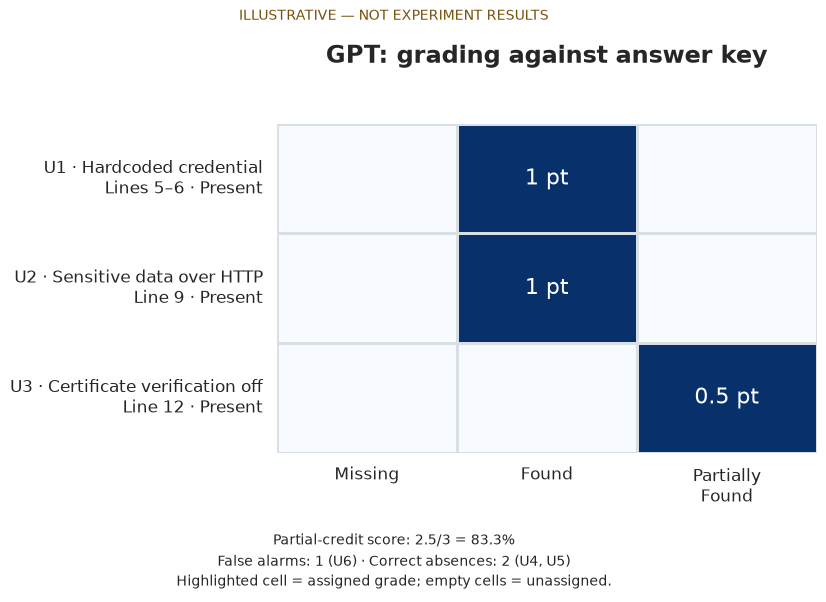

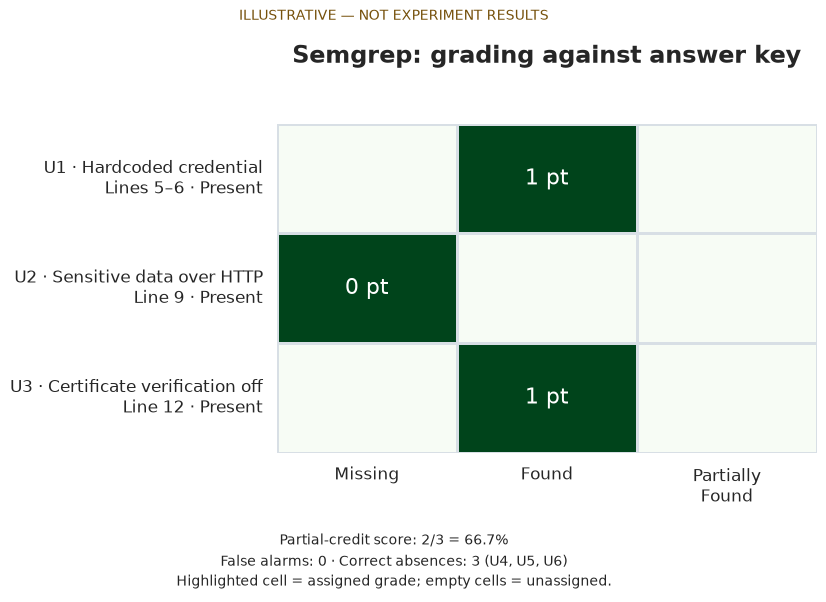

In [2]:
def finish(fig, filename, note):
    fig.text(0.5, 0.975, "ILLUSTRATIVE — NOT EXPERIMENT RESULTS",
             ha="center", va="top", fontsize=10, color="#76510c")
    fig.text(0.5, 0.035, note, ha="center", va="bottom", fontsize=10, linespacing=1.5)
    fig.savefig(OUT / filename, facecolor="white", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def heatmap(ax, data, annotations, cmap, ticks_x, ticks_y, maximum):
    sns.heatmap(data, annot=annotations, fmt="", cmap=cmap, vmin=0, vmax=maximum,
                cbar=False, linewidths=1, linecolor="#d8dfe5",
                xticklabels=ticks_x, yticklabels=ticks_y,
                annot_kws={"fontsize": 16}, ax=ax)
    ax.set_yticklabels(ticks_y, rotation=0)
    ax.tick_params(axis="both", length=0, pad=10)

grade_ticks = ["Missing", "Found", "Partially\nFound"]
row_labels = ["U1 · Hardcoded credential\nLines 5–6 · Present",
              "U2 · Sensitive data over HTTP\nLine 9 · Present",
              "U3 · Certificate verification off\nLine 12 · Present"]
for detector, cmap, filename, controls in [
    ("GPT", "Blues", "comparison-gpt-grading.png", "False alarms: 1 (U6) · Correct absences: 2 (U4, U5)"),
    ("Semgrep", "Greens", "comparison-semgrep-grading.png", "False alarms: 0 · Correct absences: 3 (U4, U5, U6)"),
]:
    indicator = np.array([[int(grade == category) for category in categories] for grade in grades[detector]])
    annotation = np.array([[f"{points[cat]:g} pt" if value else ""
                            for cat, value in zip(categories, row)] for row in indicator])
    fig, ax = plt.subplots(figsize=(9, 6.2))
    fig.subplots_adjust(left=0.37, right=0.97, top=0.79, bottom=0.26)
    heatmap(ax, indicator, annotation, cmap, grade_ticks, row_labels, 1)
    ax.set_xlabel("")  # Grade names are directly labeled on the columns.
    ax.set_title(f"{detector}: grading against answer key", pad=44, fontsize=17, weight="bold")
    earned = grades[detector].map(points).sum()
    finish(fig, filename, f"Partial-credit score: {earned:g}/3 = {scores[detector]:.1f}%\n"
           f"{controls}\nHighlighted cell = assigned grade; empty cells = unassigned.")

## Grade agreement: GPT vs Semgrep
This 3 × 3 cross-tabulation compares evaluator-assigned grades on U1–U3, not true code classes. U4–U6 are excluded because false alarms/correct absences are not grades for known vulnerabilities.

Exact grade agreement is **1/3 = 33.3%** (U1 only).

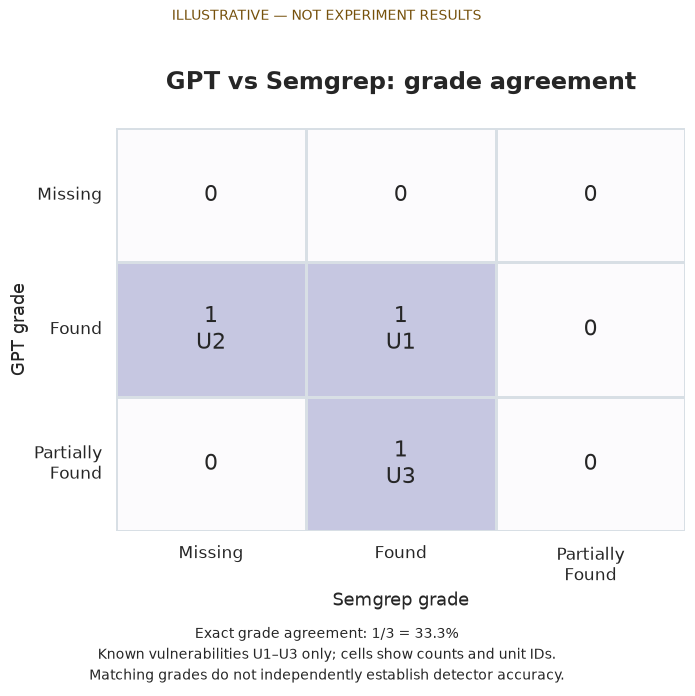

In [3]:
def cross_tab(row_values, column_values, labels, ids):
    counts = np.zeros((len(labels), len(labels)), dtype=int)
    members = [[[] for _ in labels] for _ in labels]
    for unit, row, col in zip(ids, row_values, column_values):
        i, j = labels.index(row), labels.index(col)
        counts[i, j] += 1
        members[i][j].append(unit)
    annotations = np.array([[str(counts[i,j]) + ("\n" + ", ".join(members[i][j]) if members[i][j] else "")
                             for j in range(len(labels))] for i in range(len(labels))])
    return counts, members, annotations

grade_counts, grade_members, annotation = cross_tab(grades["GPT"], grades["Semgrep"], categories, units[:3])
fig, ax = plt.subplots(figsize=(7.8, 7.2))
fig.subplots_adjust(left=0.23, right=0.96, top=0.81, bottom=0.25)
heatmap(ax, grade_counts, annotation, "Purples", grade_ticks, grade_ticks, 3)
ax.set(xlabel="Semgrep grade", ylabel="GPT grade")
ax.set_title("GPT vs Semgrep: grade agreement", pad=28, fontsize=17, weight="bold")
finish(fig, "comparison-grading-agreement.png",
       f"Exact grade agreement: {np.trace(grade_counts)}/3 = {np.trace(grade_counts)/3:.1%}\n"
       "Known vulnerabilities U1–U3 only; cells show counts and unit IDs.\n"
       "Matching grades do not independently establish detector accuracy.")

## Checks and exports
These checks verify consistency of invented outcomes, not actual detector performance. This notebook performs no API calls, scanner runs or execution of the sample IoT code.

In [4]:
assert np.isclose(scores["GPT"], 100 * 2.5 / 3)
assert np.isclose(scores["Semgrep"], 100 * 2 / 3)
assert grade_counts.tolist() == [[0, 0, 0], [1, 1, 0], [0, 1, 0]]
assert grade_counts.sum() == 3 and grade_counts.trace() == 1
files = ["comparison-gpt-grading.png", "comparison-semgrep-grading.png",
         "comparison-grading-agreement.png"]
assert all((OUT / name).exists() for name in files)
assert {p.name for p in OUT.glob("comparison-*.png")} == set(files)
print("All scoring, matrix and export checks passed. Exactly three comparison PNGs remain.")
print("\n".join(files))

All scoring, matrix and export checks passed. Exactly three comparison PNGs remain.
comparison-gpt-grading.png
comparison-semgrep-grading.png
comparison-grading-agreement.png
